# Testing the data reader

Drives `shape_modeling.io.reader` against a data directory so you can confirm each case
is read correctly: which files are the MRI sequences, which are organ (anatomy) vs
cancer (tumor) segmentations, how many reader annotations there are, and that masks line
up with the MRI.

**Setup:** `pip install -r requirements-dev.txt`, then run top to bottom. Point
`DATA_DIR` at either a single patient directory (e.g. `.../021`) or a parent folder
containing one subdirectory per patient.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from shape_modeling.io.reader import discover_cases

# A single patient directory, or a parent of patient directories.
DATA_DIR = Path("/Users/zoereinke/Repositories/ShapeModeling/Prostate158")

# Fallback sequence label for MRIs whose filename gives no hint (e.g. PROMISE12).
DEFAULT_MRI_TYPE = None

assert DATA_DIR.is_dir(), f"Data directory not found: {DATA_DIR}"

## 1. Discover and summarize

`discover_cases` scans the folder, groups files into per-patient `Case` objects,
classifies each volume, and loads the pixel data. `summary()` is the at-a-glance check.

In [2]:
ds = discover_cases(DATA_DIR, default_mri_type=DEFAULT_MRI_TYPE)
print(ds.summary())

case         sequences          organ  cancer  geom 
----------------------------------------------------
020          ADC,DWI,T2         1      3       ok   
021          ADC,DWI,T2         1      3       ok   
022          ADC,DWI,T2         1      0       ok   
----------------------------------------------------
3 case(s); 2 with cancer segmentation


## 2. Inspect one case in detail

Lists every MRI sequence and every segmentation the reader found for a case, with the
resolved role, sequence, annotator (reader), dtype, label count, and geometry. Change
`CASE_INDEX` to look at a different case.

In [3]:
CASE_INDEX = 0
case = ds.cases[CASE_INDEX]
print(f"Case: {case.case_id}  (geometry_consistent={case.geometry_consistent})\n")

print("MRI sequences:")
for seq, vol in case.mris.items():
    print(f"  {seq:<5} {vol.path.name:<28} dtype={vol.dtype:<22} "
          f"size={vol.size} intensity={vol.intensity_range}")

print("\nOrgan (anatomy) segmentations:")
for vol in case.organ_segs:
    print(f"  {vol.path.name:<32} on={vol.sequence}  reader={vol.reader}  labels={vol.num_labels}")

print("\nCancer (tumor) segmentations:")
for vol in case.cancer_segs:
    print(f"  {vol.path.name:<32} on={vol.sequence}  reader={vol.reader}  labels={vol.num_labels}")
if not case.cancer_segs:
    print("  (none — no tumor for this case)")

Case: 020  (geometry_consistent=True)

MRI sequences:
  ADC   adc.nii.gz                   dtype=32-bit float           size=(270, 270, 24) intensity=(0.0, 2906.235107421875)
  DWI   dwi.nii.gz                   dtype=32-bit float           size=(270, 270, 24) intensity=(0.0, 131.44720458984375)
  T2    t2.nii.gz                    dtype=32-bit float           size=(270, 270, 24) intensity=(0.0, 1162.0)

Organ (anatomy) segmentations:
  t2_anatomy_reader1.nii.gz        on=T2  reader=reader1  labels=3

Cancer (tumor) segmentations:
  adc_tumor_reader1.nii.gz         on=ADC  reader=reader1  labels=2
  adc_tumor_reader2.nii.gz         on=ADC  reader=reader2  labels=2
  t2_tumor_reader1.nii.gz          on=T2  reader=reader1  labels=2


## 3. Visualize: MRI slice with segmentation overlay

Overlays the organ and tumor masks that were drawn on the chosen sequence onto that
sequence's MRI. The clearest correctness check — the masks should sit on the anatomy.
SimpleITK arrays are `[z, y, x]`, so axis 0 is the slice axis; we pick the slice with the
most segmented voxels.

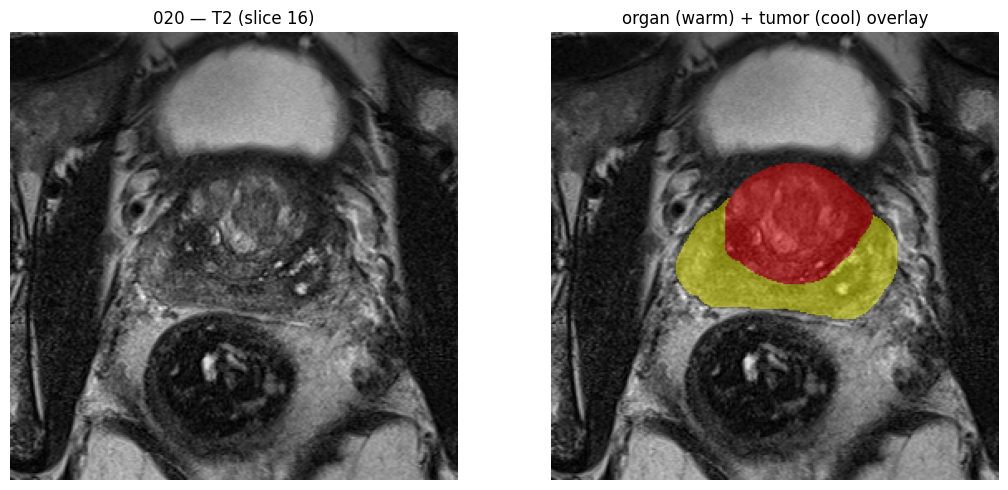

In [4]:
# Pick which sequence to view (defaults to the primary / T2 MRI).
SEQUENCE = case.primary_mri.sequence if case.primary_mri else None
mri_vol = case.mris.get(SEQUENCE) or case.primary_mri
mri = mri_vol.array

# Masks drawn on this sequence (fall back to all masks if sequence wasn't recorded).
organs = [s for s in case.organ_segs if s.sequence in (SEQUENCE, None)] or case.organ_segs
cancers = [s for s in case.cancer_segs if s.sequence in (SEQUENCE, None)] or case.cancer_segs

# Slice with the most segmented voxels (prefer organ, else tumor, else middle).
ref_mask = (organs or cancers)
if ref_mask:
    m = ref_mask[0].array
    z = int((m != 0).reshape(m.shape[0], -1).sum(axis=1).argmax())
else:
    z = mri.shape[0] // 2

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(mri[z], cmap="gray")
axes[0].set_title(f"{case.case_id} — {SEQUENCE} (slice {z})")

axes[1].imshow(mri[z], cmap="gray")
for s in organs:
    axes[1].imshow(np.ma.masked_where(s.array[z] == 0, s.array[z]), cmap="autumn", alpha=0.45)
for s in cancers:
    axes[1].imshow(np.ma.masked_where(s.array[z] == 0, s.array[z]), cmap="winter", alpha=0.55)
axes[1].set_title("organ (warm) + tumor (cool) overlay")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Browse every case

One overlay per case (primary sequence). The slice shown is the one with the most
**tumor** voxels when a cancer segmentation exists, otherwise the busiest organ slice —
so cancerous cases always display the lesion. Scan for any misaligned or missing mask.

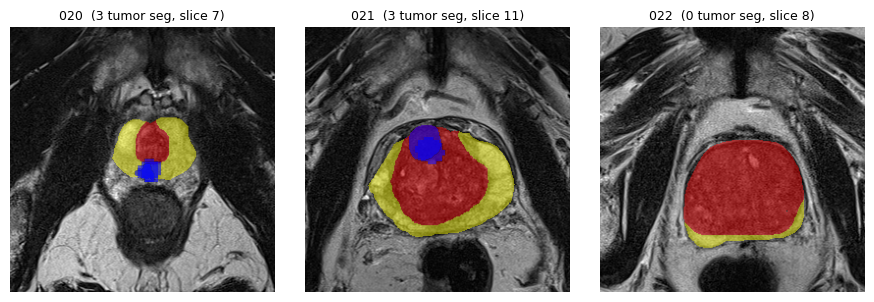

In [5]:
n = len(ds.cases)
cols = min(4, n)
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows), squeeze=False)
axes = axes.ravel()


def busiest_slice(masks, n_slices):
    """Index of the slice containing the most nonzero voxels across `masks`, or None."""
    counts = np.zeros(n_slices, dtype=int)
    for s in masks:
        if s.array.shape[0] != n_slices:
            continue  # different geometry; can't index against this MRI
        nz = s.array != 0
        counts += nz.reshape(nz.shape[0], -1).sum(axis=1)
    return int(counts.argmax()) if counts.any() else None


for ax, c in zip(axes, ds.cases):
    mri_vol = c.primary_mri
    if mri_vol is None:
        ax.set_title(f"{c.case_id} (no MRI)", fontsize=9)
        ax.axis("off")
        continue
    mri = mri_vol.array

    # Show a slice that actually contains tumor when there is one; otherwise the slice
    # with the most organ; otherwise the middle slice.
    z = busiest_slice(c.cancer_segs, mri.shape[0])
    if z is None:
        z = busiest_slice(c.organ_segs, mri.shape[0])
    if z is None:
        z = mri.shape[0] // 2

    ax.imshow(mri[z], cmap="gray")
    if c.organ_segs:
        organ = c.organ_segs[0].array
        if organ.shape[0] == mri.shape[0]:
            ax.imshow(np.ma.masked_where(organ[z] == 0, organ[z]), cmap="autumn", alpha=0.45)
    for s in c.cancer_segs:
        if s.array.shape[0] == mri.shape[0]:
            ax.imshow(np.ma.masked_where(s.array[z] == 0, s.array[z]), cmap="winter", alpha=0.55)
    ax.set_title(f"{c.case_id}  ({len(c.cancer_segs)} tumor seg, slice {z})", fontsize=9)
    ax.axis("off")

for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Quality control

Runs the QC checks (image integrity, mask validity, cross-mask) over every case and prints
a report. `worst` is `clean` when a case has no findings. Warnings/errors are listed in
detail so you can spot bad masks before they enter the shape model — e.g. disconnected
islands, FOV-truncated organs, implausible volumes, or a tumor drawn outside the gland.

In [6]:
from shape_modeling.qc import QCConfig, run_qc

# Thresholds default to prostate-plausible values; pass a QCConfig for other organs, e.g.
# run_qc(ds, QCConfig(organ_volume_range_cm3=(2.0, 40.0)))  # thyroid
report = run_qc(ds)
print(report.summary())

# Inspect machine-readable findings (e.g. to decide which cases to exclude from the SSM):
print("\nPassed (no errors):", report.passed)
for f in report.warnings() + report.errors():
    print(f"  {f.severity.value:<7} {f.case_id} · {f.target} · {f.check}: {f.message}  (value={f.value})")

case         info  warn  error  worst   
----------------------------------------
020          6     0     0      info    
021          6     1     0      warning 
022          0     0     0      clean   
----------------------------------------
3 case(s); 1 warning(s); PASS (no errors)

Findings (warnings + errors):
  [warning] 021 · t2_tumor_reader1.nii.gz · mask.components: 4 tiny island(s) < 10 voxels

Passed (no errors): True
  warning 021 · t2_tumor_reader1.nii.gz · mask.components: 4 tiny island(s) < 10 voxels  (value=4)
